In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Step 1: Read the dataset
df = pd.read_csv('Churn_Modelling.csv')

df.fillna(df.median(numeric_only = True), inplace=True)

le_gender = LabelEncoder()
df['Gender'] = le_gender.fit_transform(df['Gender'])

df = pd.get_dummies(df, columns=['Geography'], drop_first=True)

X = df.drop(columns=['RowNumber', 'CustomerId', 'Surname', 'Exited'])
y = df['Exited']

# Divide dataset into training (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Step 3: Normalize the train and test data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data Preprocessing Complete!")
print("X_train shape:", X_train_scaled.shape)
print("X_test shape:", X_test_scaled.shape)

                                 

Data Preprocessing Complete!
X_train shape: (8000, 11)
X_test shape: (2000, 11)


In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['Gender'] = le.fit_transform(df['Gender'])

pd.get_dummies(df, columns=['Geography'], drop_first=True)

In [12]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

model = Sequential([ Dense(units = 32, activation='relu', input_dim=X_train_scaled.shape[1]), Dropout(0.2), Dense(units = 16, activation='relu'), Dropout(0.1), Dense(units=1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy']) 
history = model.fit(X_train_scaled, y_train, batch_size = 32, epochs=50, validation_split=0.1, verbose=1)



Epoch 1/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7958 - loss: 0.4901 - val_accuracy: 0.8300 - val_loss: 0.4104
Epoch 2/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8097 - loss: 0.4447 - val_accuracy: 0.8462 - val_loss: 0.3940
Epoch 3/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8161 - loss: 0.4289 - val_accuracy: 0.8438 - val_loss: 0.3803
Epoch 4/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8181 - loss: 0.4194 - val_accuracy: 0.8525 - val_loss: 0.3722
Epoch 5/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8242 - loss: 0.4121 - val_accuracy: 0.8550 - val_loss: 0.3618
Epoch 6/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8300 - loss: 0.4039 - val_accuracy: 0.8587 - val_loss: 0.3512
Epoch 7/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8310 - loss: 0.3966 - val_accuracy: 0.8637 - val_loss: 0.3457
Epoch 8/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8431 - loss: 0.3821 - val_accuracy: 0.

In [3]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dropout, Dense

model = Sequential([Dense(units=32, activation='relu', input_dim=X_train_scaled.shape[1]), Dropout(0.2), Dense(units=16, activation='relu'), Dropout(0.1), Dense(units=1, activation='sigmoid')])

model.compile(loss='binary_crossentropy')

model.fit(X_train_scaled, y_train, epochs = 50)

250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5151


model = Sequential([
Dense(units = 32, activation='relu', input_dim=X_train_scaled.shape[1]),
Dropout(0.2),
Dense(units = 16, activation='relu').
Dropout(0.1),
Dense(units=1, activation='sigmoid')

])

model.compile(optimizer='adam', loss='binary crossentropy', metrics=['accuracy'])
history = model.fit(X_train_scaled, y_train, batch_size = 32, epochs=50, validation_split=0.1, verbose=1)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
--- Model Performance ---
Accuracy Score: 85.90%

Classification Report:
               precision    recall  f1-score   support

   Stays (0)       0.87      0.97      0.92      1593
   Exits (1)       0.80      0.41      0.54       407

    accuracy                           0.86      2000
   macro avg       0.83      0.69      0.73      2000
weighted avg       0.85      0.86      0.84      2000



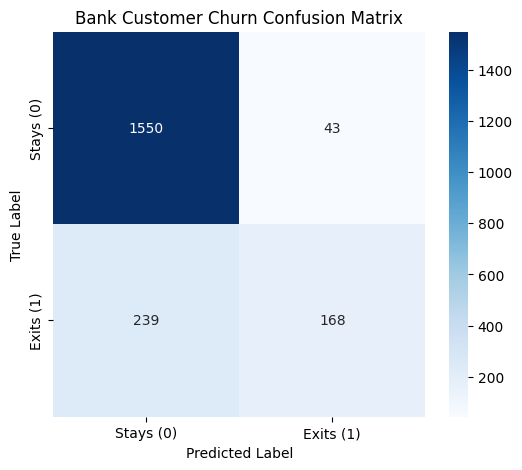

In [13]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Generate predictions (Sigmoid outputs probabilities from 0 to 1)
y_pred_prob = model.predict(X_test_scaled)

# Convert probabilities to binary predictions (>= 0.5 -> 1, else -> 0)
y_pred = (y_pred_prob >= 0.5).astype(int)

# 2. Print Accuracy Score (Step 5)
acc = accuracy_score(y_test, y_pred)
print(f"--- Model Performance ---")
print(f"Accuracy Score: {acc * 100:.2f}%")

# 3. Print Detailed Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=['Stays (0)', 'Exits (1)']))

# 4. Compute and Plot Confusion Matrix (Step 5)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Stays (0)', 'Exits (1)'], 
            yticklabels=['Stays (0)', 'Exits (1)'])
plt.title('Bank Customer Churn Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()